In [57]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import ExtraTreesRegressor, IsolationForest
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C

# ===============================
# FILE / COLUMNS
# ===============================
CSV_PATH    = "Paper.csv"
PACKING_COL = "Packing density"
YIELD_COL   = "yeild stress"
VISC_COL    = "viscosity"

# ===============================
# PARAMETERS
# ===============================
RANDOM_STATE = 42
TEST_SIZE    = 0.2
CV_SPLITS    = 5

IQR_K                 = 1
OUTLIER_CONTAMINATION = 0.04
RESIDUAL_Z            = 1


# ===============================
# HELPERS
# ===============================
def to_numeric(s: pd.Series) -> pd.Series:
    s = s.astype(str).str.replace(",", ".", regex=False)
    s = s.replace(["nan", "NaN", "None", ""], np.nan)
    return pd.to_numeric(s, errors="coerce")

def rmse(y, yhat) -> float:
    return float(np.sqrt(mean_squared_error(y, yhat)))

def eval_metrics(y_true, y_pred) -> dict:
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }

def filter_iqr(df: pd.DataFrame, col: str, k: float = 1.5) -> pd.DataFrame:
    x = df[col].dropna().values
    if len(x) < 10:
        return df.copy()
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    if iqr == 0:
        return df.copy()
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return df[df[col].between(lo, hi)].copy()

def filter_isoforest_xy(df: pd.DataFrame, x_col: str, y_col: str,
                        contamination: float = 0.1, rs: int = 42) -> pd.DataFrame:
    dxy = df[[x_col, y_col]].dropna()
    if len(dxy) < 20:
        return df.copy()
    iso = IsolationForest(
        n_estimators=800,
        contamination=contamination,
        random_state=rs
    )
    lab = iso.fit_predict(dxy.values)  # 1=inlier, -1=outlier
    keep_idx = dxy.index[lab == 1]
    return df.loc[keep_idx].copy()

def residual_filter(df: pd.DataFrame, x_col: str, y_col: str, z: float = 2.5) -> pd.DataFrame:
    if len(df) < 30:
        return df.copy()

    X = df[[x_col]].values
    y = df[y_col].values

    base = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KernelRidge(kernel="rbf", alpha=1e-2, gamma=1.0))
    ])
    base_t = TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)
    base_t.fit(X, y)
    pred = base_t.predict(X)
    resid = y - pred

    med = np.median(resid)
    mad = np.median(np.abs(resid - med)) + 1e-9
    zscore = 0.6745 * (resid - med) / mad

    keep = np.abs(zscore) <= z
    return df.loc[df.index[keep]].copy()

def preprocess_for_target(df_raw: pd.DataFrame, x_col: str, y_col: str) -> pd.DataFrame:
    d0 = df_raw.dropna(subset=[x_col, y_col]).copy()
    d0 = d0[(d0[x_col] > 0) & (d0[y_col] > 0)].copy()

    d1 = filter_iqr(d0, x_col, k=IQR_K)
    d1 = filter_iqr(d1, y_col, k=IQR_K)

    d2 = filter_isoforest_xy(d1, x_col, y_col,
                             contamination=OUTLIER_CONTAMINATION,
                             rs=RANDOM_STATE)

    d3 = residual_filter(d2, x_col, y_col, z=RESIDUAL_Z)
    return d3

def split_xy(df_clean: pd.DataFrame, x_col: str, y_col: str):
    X = df_clean[[x_col]].values
    y = df_clean[y_col].values
    return train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

def print_train_test(name: str, model, Xtr, ytr, Xte, yte):
    pred_tr = model.predict(Xtr)
    pred_te = model.predict(Xte)
    m_tr = eval_metrics(ytr, pred_tr)
    m_te = eval_metrics(yte, pred_te)

    print("\n" + "-"*78)
    print(f"{name} | TRAIN: R2={m_tr['R2']:.3f}, RMSE={m_tr['RMSE']:.3f}, MAE={m_tr['MAE']:.3f}")
    print(f"{name} | TEST : R2={m_te['R2']:.3f}, RMSE={m_te['RMSE']:.3f}, MAE={m_te['MAE']:.3f}")
    print("-"*78)

# ===============================
# LOAD + CHOOSE TARGET
# ===============================
df = pd.read_csv(CSV_PATH)
df[PACKING_COL] = to_numeric(df[PACKING_COL])
df[YIELD_COL]   = to_numeric(df[YIELD_COL])
df[VISC_COL]    = to_numeric(df[VISC_COL])

# ---- انتخاب هدف (یکی را فعال کن)
TARGET_COL = YIELD_COL      # یا: VISC_COL
TARGET_NAME = "Yield stress" # یا: "Viscosity"

d_clean = preprocess_for_target(df, PACKING_COL, TARGET_COL)
Xtr, Xte, ytr, yte = split_xy(d_clean, PACKING_COL, TARGET_COL)

cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"\nTARGET = {TARGET_NAME} | N(clean) = {len(d_clean)} | Train={len(ytr)} | Test={len(yte)}")



TARGET = Yield stress | N(clean) = 91 | Train=72 | Test=19


SVR

In [58]:
# ===============================
# SVR (RBF) + GridSearchCV
# ===============================
svr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", SVR(kernel="rbf"))
])
svr = TransformedTargetRegressor(regressor=svr_pipe, func=np.log1p, inverse_func=np.expm1)

svr_grid = {
    "regressor__reg__C": [5, 10, 50, 200, 500, 1000],
    "regressor__reg__gamma": ["scale", 0.05, 0.1, 0.5, 1, 2, 5],
    "regressor__reg__epsilon": [0.001, 0.01, 0.03, 0.05, 0.1],
}

svr_gs = GridSearchCV(svr, svr_grid, scoring="r2", cv=cv, n_jobs=-1)
svr_gs.fit(Xtr, ytr)

best_svr = svr_gs.best_estimator_
print("\nSVR_RBF | bestCV_R2 =", round(svr_gs.best_score_, 3))
print("SVR_RBF | best_params =", svr_gs.best_params_)

print_train_test("SVR_RBF", best_svr, Xtr, ytr, Xte, yte)



SVR_RBF | bestCV_R2 = 0.961
SVR_RBF | best_params = {'regressor__reg__C': 5, 'regressor__reg__epsilon': 0.1, 'regressor__reg__gamma': 2}

------------------------------------------------------------------------------
SVR_RBF | TRAIN: R2=0.970, RMSE=2.756, MAE=1.968
SVR_RBF | TEST : R2=0.948, RMSE=3.349, MAE=2.416
------------------------------------------------------------------------------


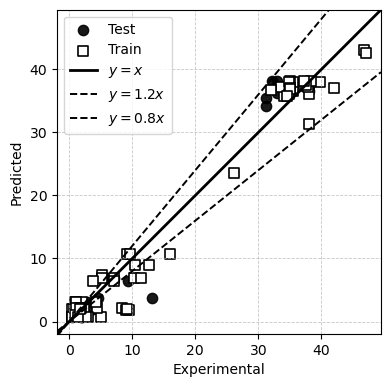

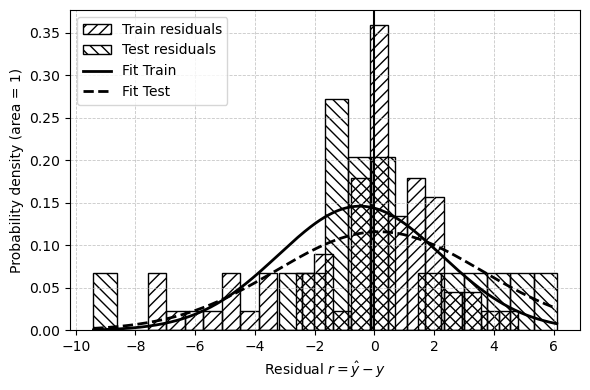

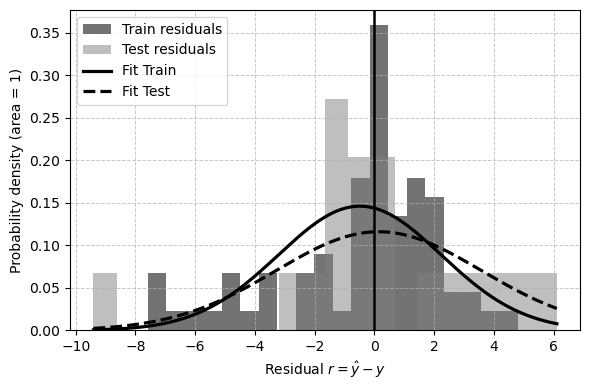

Saved: pred_vs_exp.png | residual_hist_hatch.png | residual_hist_filled.png


In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS
# ===============================
SCATTER_OUT         = "pred_vs_exp.png"
RESIDUAL_HATCH_OUT  = "residual_hist_hatch.png"
RESIDUAL_FILLED_OUT = "residual_hist_filled.png"

# ===============================
# PREDICTIONS + RESIDUALS
# ===============================
pred_tr = best_svr.predict(Xtr)
pred_te = best_svr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

# Train/Test markers: square vs triangle (BW)
#ax1.scatter(ytr, pred_tr, c="black", marker="s", s=40, alpha=0.7, label="Train")
ax1.scatter(yte, pred_te, c="black",  marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(ytr, pred_tr,
            facecolors="white", edgecolors="black",
            marker="s", s=45, linewidths=1.2,
            label="Train")

# Limits + padding
all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

# Reference lines
ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental")
ax1.set_ylabel("Predicted")

ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)

ax1.legend()
fig1.tight_layout()

fig1.savefig(SCATTER_OUT, dpi=300, bbox_inches="tight")
plt.show()


# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)


# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching (your current style)
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")


ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
#ax2a.legend()
ax2a.legend(loc="upper left")
fig2a.tight_layout()

fig2a.savefig(RESIDUAL_HATCH_OUT, dpi=300, bbox_inches="tight")
plt.show()

# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

# Darker filled histograms
ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")   # very dark gray

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")    # mid-dark gray

# Fit curves (thicker for contrast)

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")


# Zero line (slightly thicker)
ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2b.set_ylabel("Probability density (area = 1)")

ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
#ax2b.legend()
#ax2b.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax2b.legend(loc="upper left")

fig2b.tight_layout()

fig2b.savefig(RESIDUAL_FILLED_OUT, dpi=300, bbox_inches="tight")
plt.show()



print("Saved:", SCATTER_OUT, "|", RESIDUAL_HATCH_OUT, "|", RESIDUAL_FILLED_OUT)


KRR

In [60]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV

# ===============================
# KRR (RBF) + GridSearchCV
# ===============================
krr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", KernelRidge(kernel="rbf"))
])
krr = TransformedTargetRegressor(regressor=krr_pipe, func=np.log1p, inverse_func=np.expm1)

krr_grid = {
    # KernelRidge hyperparameters
    "regressor__reg__alpha": [1e-4, 1e-3, 1e-2, 5e-2, 1e-1, 5e-1, 1.0],
    "regressor__reg__gamma": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0],
}

krr_gs = GridSearchCV(krr, krr_grid, scoring="r2", cv=cv, n_jobs=-1)
krr_gs.fit(Xtr, ytr)

best_krr = krr_gs.best_estimator_
print("\nKRR_RBF | bestCV_R2 =", round(krr_gs.best_score_, 3))
print("KRR_RBF | best_params =", krr_gs.best_params_)

print_train_test("KRR_RBF", best_krr, Xtr, ytr, Xte, yte)



KRR_RBF | bestCV_R2 = 0.965
KRR_RBF | best_params = {'regressor__reg__alpha': 0.01, 'regressor__reg__gamma': 5.0}

------------------------------------------------------------------------------
KRR_RBF | TRAIN: R2=0.978, RMSE=2.348, MAE=1.703
KRR_RBF | TEST : R2=0.930, RMSE=3.872, MAE=2.734
------------------------------------------------------------------------------


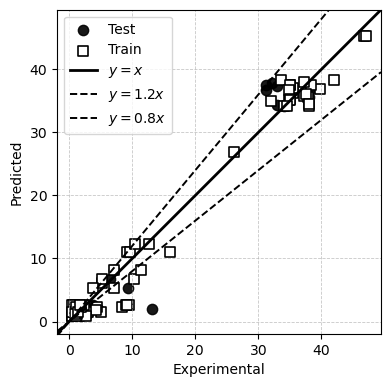

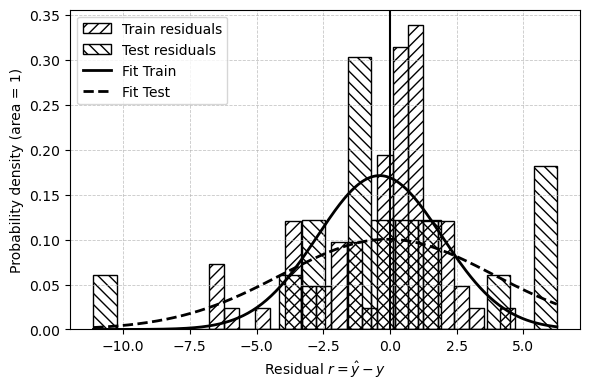

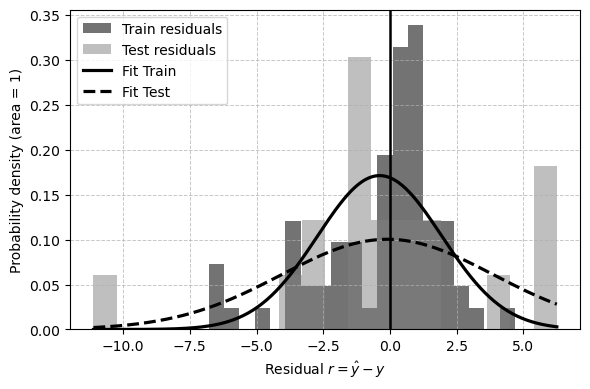

KRR Saved: pred_vs_exp_KRR.png | residual_hist_hatch_KRR.png | residual_hist_filled_KRR.png


In [62]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS (KRR)
# ===============================
SCATTER_OUT_KRR         = "pred_vs_exp_KRR.png"
RESIDUAL_HATCH_OUT_KRR  = "residual_hist_hatch_KRR.png"
RESIDUAL_FILLED_OUT_KRR = "residual_hist_filled_KRR.png"

# ===============================
# PREDICTIONS + RESIDUALS (KRR)
# ===============================
pred_tr = best_krr.predict(Xtr)
pred_te = best_krr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental (same style)
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

ax1.scatter(yte, pred_te, c="black", marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(
    ytr, pred_tr,
    facecolors="white", edgecolors="black",
    marker="s", s=45, linewidths=1.2,
    label="Train"
)

# Limits + padding
all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

# Reference lines
ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental")
ax1.set_ylabel("Predicted")
ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)

ax1.legend()
fig1.tight_layout()
fig1.savefig(SCATTER_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()


# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)


# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching (same style)
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")

ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax2a.legend(loc="upper left")

fig2a.tight_layout()
fig2a.savefig(RESIDUAL_HATCH_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()


# ===============================
# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER (same style)
# ===============================
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")

ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2b.set_ylabel("Probability density (area = 1)")
ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
ax2b.legend(loc="upper left")

fig2b.tight_layout()
fig2b.savefig(RESIDUAL_FILLED_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()

print("KRR Saved:", SCATTER_OUT_KRR, "|", RESIDUAL_HATCH_OUT_KRR, "|", RESIDUAL_FILLED_OUT_KRR)


ETR

In [47]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor

# ===============================
# ETR + GridSearchCV
# ===============================
etr = TransformedTargetRegressor(
    regressor=ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    func=np.log1p,
    inverse_func=np.expm1
)

etr_grid = {
    "regressor__n_estimators": [300, 600, 1000],
    "regressor__max_depth": [None, 8, 12, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", "log2", 1.0],
}

etr_gs = GridSearchCV(etr, etr_grid, scoring="r2", cv=cv, n_jobs=-1)
etr_gs.fit(Xtr, ytr)

best_etr = etr_gs.best_estimator_
print("\nETR | bestCV_R2 =", round(etr_gs.best_score_, 3))
print("ETR | best_params =", etr_gs.best_params_)

print_train_test("ETR", best_etr, Xtr, ytr, Xte, yte)



ETR | bestCV_R2 = 0.97
ETR | best_params = {'regressor__max_depth': 12, 'regressor__max_features': 'sqrt', 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 1000}

------------------------------------------------------------------------------
ETR | TRAIN: R2=0.983, RMSE=2.054, MAE=1.436
ETR | TEST : R2=0.943, RMSE=3.493, MAE=2.601
------------------------------------------------------------------------------


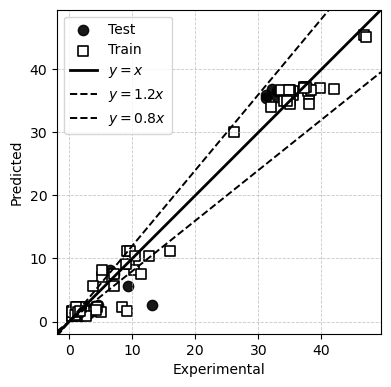

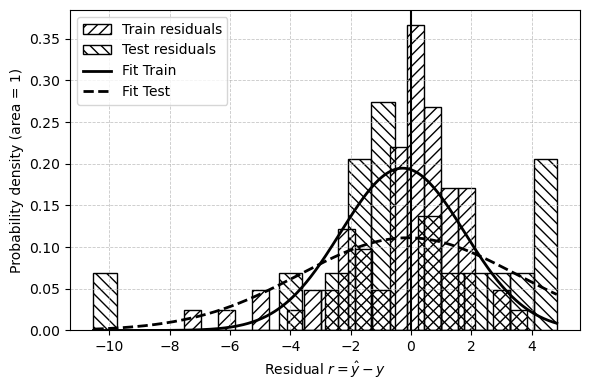

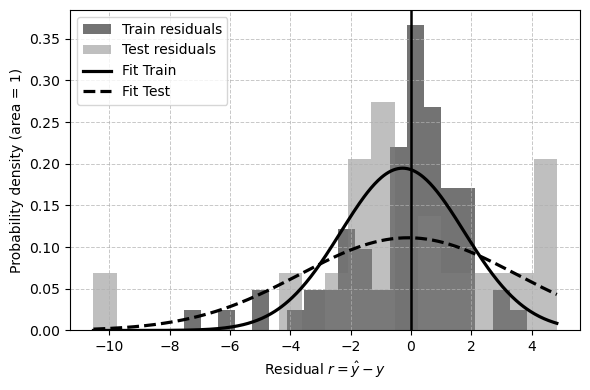

ETR Saved: pred_vs_exp_ETR.png | residual_hist_hatch_ETR.png | residual_hist_filled_ETR.png


In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS (ETR)
# ===============================
SCATTER_OUT_ETR         = "pred_vs_exp_ETR.png"
RESIDUAL_HATCH_OUT_ETR  = "residual_hist_hatch_ETR.png"
RESIDUAL_FILLED_OUT_ETR = "residual_hist_filled_ETR.png"

# ===============================
# PREDICTIONS + RESIDUALS (ETR)
# ===============================
pred_tr = best_etr.predict(Xtr)
pred_te = best_etr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental (same style)
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

ax1.scatter(yte, pred_te, c="black", marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(
    ytr, pred_tr,
    facecolors="white", edgecolors="black",
    marker="s", s=45, linewidths=1.2,
    label="Train"
)

all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental")
ax1.set_ylabel("Predicted")
ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax1.legend()

fig1.tight_layout()
fig1.savefig(SCATTER_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)

# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching (same style)
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")

ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax2a.legend(loc="upper left")

fig2a.tight_layout()
fig2a.savefig(RESIDUAL_HATCH_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER (same style)
# ===============================
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")

ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$")
ax2b.set_ylabel("Probability density (area = 1)")
ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
ax2b.legend(loc="upper left")

fig2b.tight_layout()
fig2b.savefig(RESIDUAL_FILLED_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

print("ETR Saved:", SCATTER_OUT_ETR, "|", RESIDUAL_HATCH_OUT_ETR, "|", RESIDUAL_FILLED_OUT_ETR)


Viscosity


In [76]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import IsolationForest

# ===============================
# FILE / COLUMNS
# ===============================
CSV_PATH    = "Paper.csv"
PACKING_COL = "Packing density"
YIELD_COL   = "yeild stress"
VISC_COL    = "viscosity"          # <- اگر اسم ستون پلاستیک ویسکوزیته فرق دارد این را عوض کن

# ===============================
# PARAMETERS
# ===============================
RANDOM_STATE = 42
TEST_SIZE    = 0.2
CV_SPLITS    = 5

# Outlier filters (همان مقادیر خودت)
IQR_K                 = 1
OUTLIER_CONTAMINATION = 0.04
RESIDUAL_Z            = 1

# ===============================
# HELPERS
# ===============================
def to_numeric(s: pd.Series) -> pd.Series:
    s = s.astype(str).str.replace(",", ".", regex=False)
    s = s.replace(["nan", "NaN", "None", ""], np.nan)
    return pd.to_numeric(s, errors="coerce")

def rmse(y, yhat) -> float:
    return float(np.sqrt(mean_squared_error(y, yhat)))

def eval_metrics(y_true, y_pred) -> dict:
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }

def filter_iqr(df: pd.DataFrame, col: str, k: float = 1.5) -> pd.DataFrame:
    x = df[col].dropna().values
    if len(x) < 10:
        return df.copy()
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    if iqr == 0:
        return df.copy()
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return df[df[col].between(lo, hi)].copy()

def filter_isoforest_xy(df: pd.DataFrame, x_col: str, y_col: str,
                        contamination: float = 0.1, rs: int = 42) -> pd.DataFrame:
    dxy = df[[x_col, y_col]].dropna()
    if len(dxy) < 20:
        return df.copy()
    iso = IsolationForest(
        n_estimators=800,
        contamination=contamination,
        random_state=rs
    )
    lab = iso.fit_predict(dxy.values)  # 1=inlier, -1=outlier
    keep_idx = dxy.index[lab == 1]
    return df.loc[keep_idx].copy()

def residual_filter(df: pd.DataFrame, x_col: str, y_col: str, z: float = 2.5) -> pd.DataFrame:
    if len(df) < 30:
        return df.copy()

    X = df[[x_col]].values
    y = df[y_col].values

    base = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KernelRidge(kernel="rbf", alpha=1e-2, gamma=1.0))
    ])

    # اگر پلاستیک ویسکوزیته همیشه مثبت است، log1p خوب است
    base_t = TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)

    base_t.fit(X, y)
    pred = base_t.predict(X)
    resid = y - pred

    med = np.median(resid)
    mad = np.median(np.abs(resid - med)) + 1e-9
    zscore = 0.6745 * (resid - med) / mad

    keep = np.abs(zscore) <= z
    return df.loc[df.index[keep]].copy()

def preprocess_for_target(df_raw: pd.DataFrame, x_col: str, y_col: str) -> pd.DataFrame:
    d0 = df_raw.dropna(subset=[x_col, y_col]).copy()
    d0 = d0[(d0[x_col] > 0) & (d0[y_col] > 0)].copy()

    d1 = filter_iqr(d0, x_col, k=IQR_K)
    d1 = filter_iqr(d1, y_col, k=IQR_K)

    d2 = filter_isoforest_xy(d1, x_col, y_col,
                             contamination=OUTLIER_CONTAMINATION,
                             rs=RANDOM_STATE)

    d3 = residual_filter(d2, x_col, y_col, z=RESIDUAL_Z)
    return d3

def split_xy(df_clean: pd.DataFrame, x_col: str, y_col: str):
    X = df_clean[[x_col]].values
    y = df_clean[y_col].values
    return train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

def print_train_test(name: str, model, Xtr, ytr, Xte, yte):
    pred_tr = model.predict(Xtr)
    pred_te = model.predict(Xte)
    m_tr = eval_metrics(ytr, pred_tr)
    m_te = eval_metrics(yte, pred_te)

    print("\n" + "-"*78)
    print(f"{name} | TRAIN: R2={m_tr['R2']:.3f}, RMSE={m_tr['RMSE']:.3f}, MAE={m_tr['MAE']:.3f}")
    print(f"{name} | TEST : R2={m_te['R2']:.3f}, RMSE={m_te['RMSE']:.3f}, MAE={m_te['MAE']:.3f}")
    print("-"*78)

# ===============================
# LOAD + CHOOSE TARGET (PLASTIC VISCOSITY)
# ===============================
df = pd.read_csv(CSV_PATH)
df[PACKING_COL] = to_numeric(df[PACKING_COL])
df[YIELD_COL]   = to_numeric(df[YIELD_COL])
df[VISC_COL]    = to_numeric(df[VISC_COL])

# ---- هدف: Plastic Viscosity
TARGET_COL  = VISC_COL
TARGET_NAME = "Plastic viscosity"

d_clean = preprocess_for_target(df, PACKING_COL, TARGET_COL)
Xtr, Xte, ytr, yte = split_xy(d_clean, PACKING_COL, TARGET_COL)

cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"\nTARGET = {TARGET_NAME} | N(clean) = {len(d_clean)} | Train={len(ytr)} | Test={len(yte)}")



TARGET = Plastic viscosity | N(clean) = 74 | Train=59 | Test=15


SVR

In [77]:
# ===============================
# SVR (RBF) + GridSearchCV  (Plastic Viscosity)
# ===============================
svr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", SVR(kernel="rbf"))
])

# اگر ویسکوزیته همیشه مثبت است، log1p مناسب است
svr = TransformedTargetRegressor(
    regressor=svr_pipe,
    func=np.log1p,
    inverse_func=np.expm1
)

svr_grid = {
    "regressor__reg__C": [5, 10, 50, 200, 500, 1000],
    "regressor__reg__gamma": ["scale", 0.05, 0.1, 0.5, 1, 2, 5],
    "regressor__reg__epsilon": [0.001, 0.01, 0.03, 0.05, 0.1],
}

svr_gs = GridSearchCV(svr, svr_grid, scoring="r2", cv=cv, n_jobs=-1)
svr_gs.fit(Xtr, ytr)   # ytr اینجا باید ویسکوزیته (Plastic viscosity) باشد

best_svr_visc = svr_gs.best_estimator_
print("\nSVR_RBF (Plastic viscosity) | bestCV_R2 =", round(svr_gs.best_score_, 3))
print("SVR_RBF (Plastic viscosity) | best_params =", svr_gs.best_params_)

print_train_test("SVR_RBF (Plastic viscosity)", best_svr_visc, Xtr, ytr, Xte, yte)



SVR_RBF (Plastic viscosity) | bestCV_R2 = 0.478
SVR_RBF (Plastic viscosity) | best_params = {'regressor__reg__C': 10, 'regressor__reg__epsilon': 0.01, 'regressor__reg__gamma': 0.5}

------------------------------------------------------------------------------
SVR_RBF (Plastic viscosity) | TRAIN: R2=0.856, RMSE=2.124, MAE=1.523
SVR_RBF (Plastic viscosity) | TEST : R2=0.907, RMSE=2.365, MAE=1.781
------------------------------------------------------------------------------


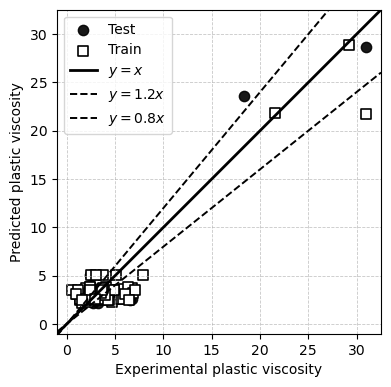

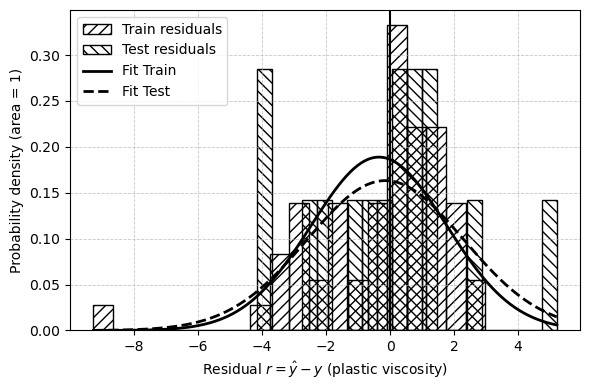

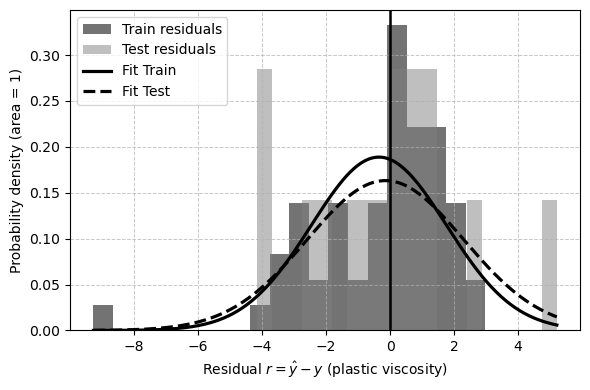

Saved: pred_vs_exp_visc.png | residual_hist_hatch_visc.png | residual_hist_filled_visc.png


In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS (Plastic Viscosity)
# ===============================
SCATTER_OUT         = "pred_vs_exp_visc.png"
RESIDUAL_HATCH_OUT  = "residual_hist_hatch_visc.png"
RESIDUAL_FILLED_OUT = "residual_hist_filled_visc.png"

# ===============================
# PREDICTIONS + RESIDUALS (use viscosity model)
# ===============================
# اگر مدل ویسکوزیته‌ات اسمش best_svr_visc است:
pred_tr = best_svr_visc.predict(Xtr)
pred_te = best_svr_visc.predict(Xte)

# اگر هنوز اسم مدل را best_svr گذاشتی، این دو خط را جایگزین کن:
# pred_tr = best_svr.predict(Xtr)
# pred_te = best_svr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental (Plastic viscosity)
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

ax1.scatter(yte, pred_te, c="black", marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(
    ytr, pred_tr,
    facecolors="white", edgecolors="black",
    marker="s", s=45, linewidths=1.2,
    label="Train"
)

# Limits + padding
all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

# Reference lines
ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental plastic viscosity")
ax1.set_ylabel("Predicted plastic viscosity")

ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax1.legend()

fig1.tight_layout()
fig1.savefig(SCATTER_OUT, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)

# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")

ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax2a.legend(loc="upper left")

fig2a.tight_layout()
fig2a.savefig(RESIDUAL_HATCH_OUT, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER
# ===============================
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")

ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2b.set_ylabel("Probability density (area = 1)")
ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
ax2b.legend(loc="upper left")

fig2b.tight_layout()
fig2b.savefig(RESIDUAL_FILLED_OUT, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", SCATTER_OUT, "|", RESIDUAL_HATCH_OUT, "|", RESIDUAL_FILLED_OUT)


KRR

In [80]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV
import numpy as np

# ===============================
# KRR (RBF) + GridSearchCV  (Plastic Viscosity)
# ===============================
krr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", KernelRidge(kernel="rbf"))
])

# اگر ویسکوزیته همیشه مثبت است، log1p مناسب است
krr = TransformedTargetRegressor(
    regressor=krr_pipe,
    func=np.log1p,
    inverse_func=np.expm1
)

krr_grid = {
    "regressor__reg__alpha": [1e-4, 1e-3, 1e-2, 5e-2, 1e-1, 5e-1, 1.0],
    "regressor__reg__gamma": [0.001,0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10],
}

krr_gs = GridSearchCV(krr, krr_grid, scoring="r2", cv=cv, n_jobs=-1)
krr_gs.fit(Xtr, ytr)   # ytr اینجا باید ویسکوزیته (Plastic viscosity) باشد

best_krr_visc = krr_gs.best_estimator_
print("\nKRR_RBF (Plastic viscosity) | bestCV_R2 =", round(krr_gs.best_score_, 3))
print("KRR_RBF (Plastic viscosity) | best_params =", krr_gs.best_params_)

print_train_test("KRR_RBF (Plastic viscosity)", best_krr_visc, Xtr, ytr, Xte, yte)



KRR_RBF (Plastic viscosity) | bestCV_R2 = 0.54
KRR_RBF (Plastic viscosity) | best_params = {'regressor__reg__alpha': 0.05, 'regressor__reg__gamma': 0.5}

------------------------------------------------------------------------------
KRR_RBF (Plastic viscosity) | TRAIN: R2=0.832, RMSE=2.293, MAE=1.621
KRR_RBF (Plastic viscosity) | TEST : R2=0.898, RMSE=2.477, MAE=1.740
------------------------------------------------------------------------------


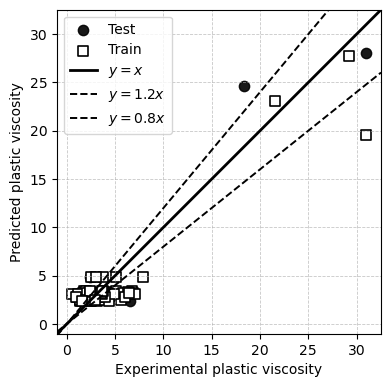

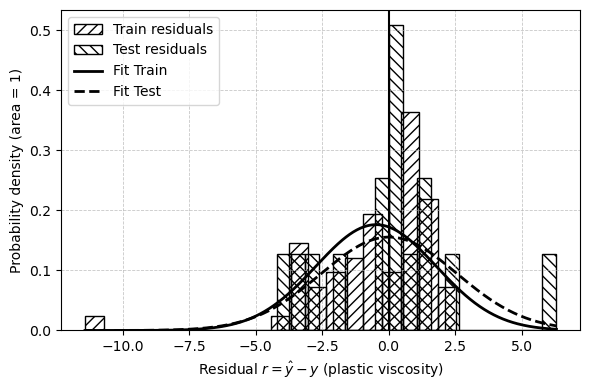

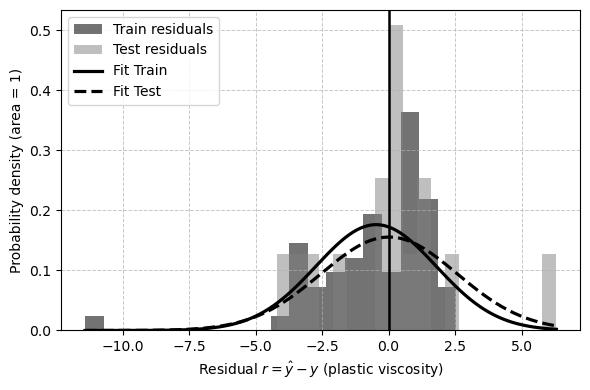

KRR (Viscosity) Saved: pred_vs_exp_KRR_visc.png | residual_hist_hatch_KRR_visc.png | residual_hist_filled_KRR_visc.png


In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS (KRR — Plastic viscosity)
# ===============================
SCATTER_OUT_KRR         = "pred_vs_exp_KRR_visc.png"
RESIDUAL_HATCH_OUT_KRR  = "residual_hist_hatch_KRR_visc.png"
RESIDUAL_FILLED_OUT_KRR = "residual_hist_filled_KRR_visc.png"

# ===============================
# PREDICTIONS + RESIDUALS (use viscosity model)
# ===============================
# اگر مدل ویسکوزیته‌ات اسمش best_krr_visc است:
pred_tr = best_krr_visc.predict(Xtr)
pred_te = best_krr_visc.predict(Xte)

# اگر اسم مدل هنوز best_krr است، این دو خط را جایگزین کن:
# pred_tr = best_krr.predict(Xtr)
# pred_te = best_krr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental (Plastic viscosity)
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

ax1.scatter(yte, pred_te, c="black", marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(
    ytr, pred_tr,
    facecolors="white", edgecolors="black",
    marker="s", s=45, linewidths=1.2,
    label="Train"
)

all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental plastic viscosity")
ax1.set_ylabel("Predicted plastic viscosity")
ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax1.legend()

fig1.tight_layout()
fig1.savefig(SCATTER_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()


# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)


# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")

ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax2a.legend(loc="upper left")

fig2a.tight_layout()
fig2a.savefig(RESIDUAL_HATCH_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()


# ===============================
# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER
# ===============================
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")

ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2b.set_ylabel("Probability density (area = 1)")
ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
ax2b.legend(loc="upper left")

fig2b.tight_layout()
fig2b.savefig(RESIDUAL_FILLED_OUT_KRR, dpi=300, bbox_inches="tight")
plt.show()

print("KRR (Viscosity) Saved:",
      SCATTER_OUT_KRR, "|",
      RESIDUAL_HATCH_OUT_KRR, "|",
      RESIDUAL_FILLED_OUT_KRR)


ETR

In [82]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor
import numpy as np

# ===============================
# ETR + GridSearchCV  (Plastic Viscosity)
# ===============================
etr_visc = TransformedTargetRegressor(
    regressor=ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    func=np.log1p,          # اگر ویسکوزیته مثبت است مناسب است
    inverse_func=np.expm1
)

etr_grid = {
    "regressor__n_estimators": [300, 600, 1000],
    "regressor__max_depth": [None, 8, 12, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", "log2", 1.0],
}

etr_gs = GridSearchCV(etr_visc, etr_grid, scoring="r2", cv=cv, n_jobs=-1)
etr_gs.fit(Xtr, ytr)   # ytr باید ویسکوزیته (Plastic viscosity) باشد

best_etr_visc = etr_gs.best_estimator_
print("\nETR (Plastic viscosity) | bestCV_R2 =", round(etr_gs.best_score_, 3))
print("ETR (Plastic viscosity) | best_params =", etr_gs.best_params_)

print_train_test("ETR (Plastic viscosity)", best_etr_visc, Xtr, ytr, Xte, yte)



ETR (Plastic viscosity) | bestCV_R2 = 0.451
ETR (Plastic viscosity) | best_params = {'regressor__max_depth': 8, 'regressor__max_features': 'log2', 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 10, 'regressor__n_estimators': 300}

------------------------------------------------------------------------------
ETR (Plastic viscosity) | TRAIN: R2=0.803, RMSE=2.489, MAE=1.676
ETR (Plastic viscosity) | TEST : R2=0.845, RMSE=3.049, MAE=2.009
------------------------------------------------------------------------------


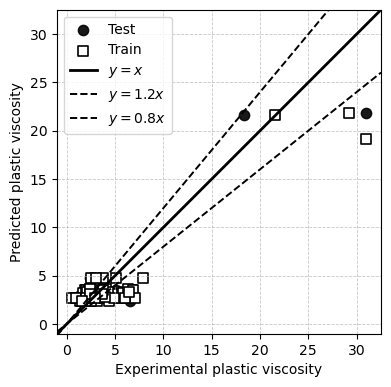

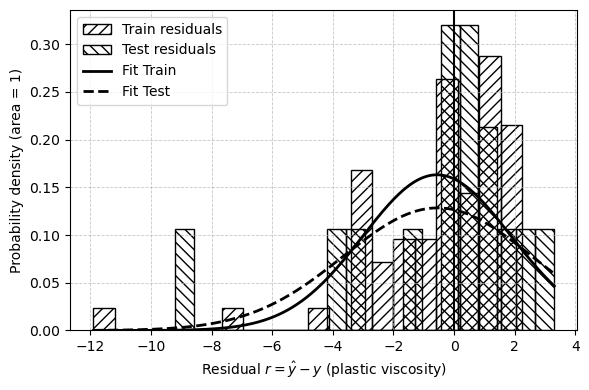

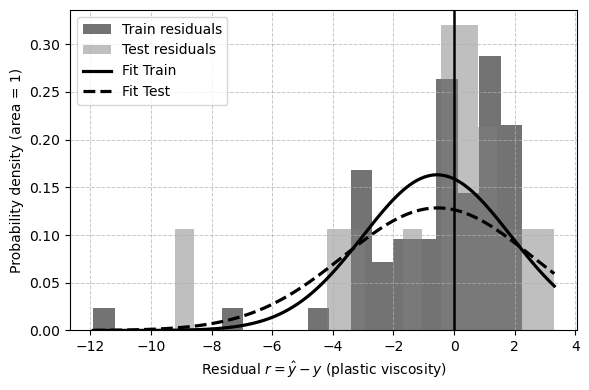

ETR (Viscosity) Saved: pred_vs_exp_ETR_visc.png | residual_hist_hatch_ETR_visc.png | residual_hist_filled_ETR_visc.png


In [83]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ===============================
# OUTPUT PATHS (ETR — Plastic viscosity)
# ===============================
SCATTER_OUT_ETR         = "pred_vs_exp_ETR_visc.png"
RESIDUAL_HATCH_OUT_ETR  = "residual_hist_hatch_ETR_visc.png"
RESIDUAL_FILLED_OUT_ETR = "residual_hist_filled_ETR_visc.png"

# ===============================
# PREDICTIONS + RESIDUALS (ETR — viscosity model)
# ===============================
pred_tr = best_etr_visc.predict(Xtr)
pred_te = best_etr_visc.predict(Xte)

# اگر هنوز اسم مدل را best_etr گذاشتی، این دو خط را جایگزین کن:
# pred_tr = best_etr.predict(Xtr)
# pred_te = best_etr.predict(Xte)

res_tr = pred_tr - ytr
res_te = pred_te - yte

# ===============================
# FIGURE 1 — Predicted vs Experimental (Plastic viscosity)
# ===============================
fig1, ax1 = plt.subplots(figsize=(4, 4))

ax1.scatter(yte, pred_te, c="black", marker="o", s=55, alpha=0.9, label="Test")
ax1.scatter(
    ytr, pred_tr,
    facecolors="white", edgecolors="black",
    marker="s", s=45, linewidths=1.2,
    label="Train"
)

all_vals = np.concatenate([ytr, yte, pred_tr, pred_te])
vmin, vmax = float(np.min(all_vals)), float(np.max(all_vals))
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
vmin -= pad
vmax += pad

xline = np.linspace(vmin, vmax, 300)

ax1.plot(xline, xline, "k-",  linewidth=2.0, label=r"$y=x$")
ax1.plot(xline, 1.2 * xline, "k--", linewidth=1.4, label=r"$y=1.2x$")
ax1.plot(xline, 0.8 * xline, "k--", linewidth=1.4, label=r"$y=0.8x$")

ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel("Experimental plastic viscosity")
ax1.set_ylabel("Predicted plastic viscosity")
ax1.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax1.legend()

fig1.tight_layout()
fig1.savefig(SCATTER_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# Shared Normal PDF fit helpers
# ===============================
mu_tr, sd_tr = float(np.mean(res_tr)), float(np.std(res_tr, ddof=1))
mu_te, sd_te = float(np.mean(res_te)), float(np.std(res_te, ddof=1))

xmin = float(min(res_tr.min(), res_te.min()))
xmax = float(max(res_tr.max(), res_te.max()))
xpdf = np.linspace(xmin, xmax, 400)

# ===============================
# FIGURE 2A — Residual Histogram (Density) with Hatching
# ===============================
fig2a, ax2a = plt.subplots(figsize=(6, 4))
bins = 20

ax2a.hist(res_tr, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="///", linewidth=1.0,
          label="Train residuals")

ax2a.hist(res_te, bins=bins, density=True,
          edgecolor="black", facecolor="none",
          hatch="\\\\\\", linewidth=1.0,
          label="Test residuals")

ax2a.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2, label="Fit Train")
ax2a.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2, label="Fit Test")

ax2a.axvline(0, color="black", linewidth=1.5)

ax2a.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2a.set_ylabel("Probability density (area = 1)")
ax2a.grid(True, linestyle="--", linewidth=0.6, alpha=0.7)
ax2a.legend(loc="upper left")

fig2a.tight_layout()
fig2a.savefig(RESIDUAL_HATCH_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

# ===============================
# FIGURE 2B — Residual Histogram (Density) FILLED — DARKER
# ===============================
fig2b, ax2b = plt.subplots(figsize=(6, 4))
bins = 20

ax2b.hist(res_tr, bins=bins, density=True,
          color="black", alpha=0.55, label="Train residuals")

ax2b.hist(res_te, bins=bins, density=True,
          color="gray", alpha=0.50, label="Test residuals")

ax2b.plot(xpdf, norm.pdf(xpdf, mu_tr, sd_tr), "k-",  linewidth=2.3, label="Fit Train")
ax2b.plot(xpdf, norm.pdf(xpdf, mu_te, sd_te), "k--", linewidth=2.3, label="Fit Test")

ax2b.axvline(0, color="black", linewidth=1.8)

ax2b.set_xlabel(r"Residual $r = \hat{y} - y$ (plastic viscosity)")
ax2b.set_ylabel("Probability density (area = 1)")
ax2b.grid(True, linestyle="--", linewidth=0.7, alpha=0.7)
ax2b.legend(loc="upper left")

fig2b.tight_layout()
fig2b.savefig(RESIDUAL_FILLED_OUT_ETR, dpi=300, bbox_inches="tight")
plt.show()

print("ETR (Viscosity) Saved:",
      SCATTER_OUT_ETR, "|",
      RESIDUAL_HATCH_OUT_ETR, "|",
      RESIDUAL_FILLED_OUT_ETR)
